<a href="https://colab.research.google.com/github/Seamuscs/Brent-and-WTI-spot-prices-spread-/blob/main/Brent%20and%20WTI%20spot%20prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
#preamble
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

brent = pd.read_csv("DCOILBRENTEU.csv")
wti = pd.read_csv("DCOILWTICO.csv")

Saving DCOILBRENTEU.csv to DCOILBRENTEU (2).csv
Saving DCOILWTICO.csv to DCOILWTICO (3).csv


Uses pandas to read csv Brent and WTI spot prices taken from FRED.

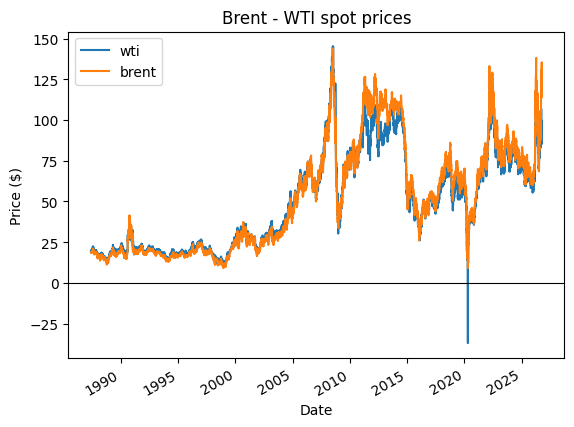

In [10]:
#cleaning data
wti["observation_date"] = pd.to_datetime(wti["observation_date"])
wti = wti.set_index("observation_date")
brent["observation_date"] = pd.to_datetime(brent["observation_date"])
brent = brent.set_index("observation_date")
  #convert the date string into a date and use it as index for the spot prices

df = pd.concat([wti, brent], axis=1, join="inner")
df.columns = ["wti", "brent"]
df.dropna(inplace=True)
bx = df.plot()
bx.set_title('Brent - WTI spot prices')
bx.set_xlabel("Date")
bx.set_ylabel("Price ($)")
bx.axhline(0, color="black", linewidth=0.8)
plt.show()
  #merge Brent and WTI and remove and days for both where prices are not available
  #plot both Brent and WTI on the same graph

Plot graphs the Brent and WTI spot prices independently. They more often than not move in unison apart from a select few cases. WTI historically falls below 0$ per barrel due to cushing. Most notably, the spot prices of oil have surged, specifically Brent, due to the closure of the straight of Hormuz. Brent relies on transport by sea as it is the benchmark for oil in the North sea. This means that for major closures of shipping routes, like we see with the straight of Hormuz, any major oil shipment between Europe and contintental Asia and Oceania is blocked and causes oil prices to surge due to lower supply.

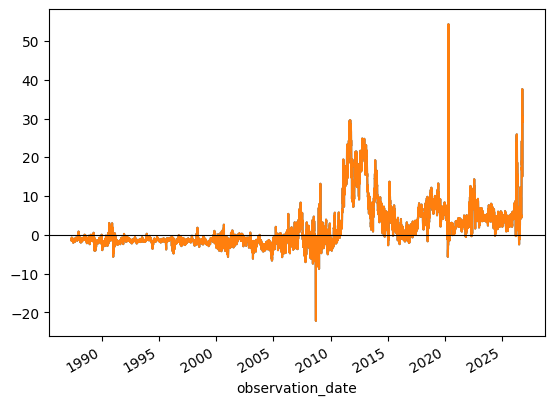

                    wti   brent  spread  spread_zscore
observation_date                                      
1987-05-20        19.75   18.63   -1.12      -0.593970
1987-05-21        19.95   18.45   -1.50      -0.661464
1987-05-22        19.68   18.55   -1.13      -0.595746
1987-05-26        19.35   18.63   -0.72      -0.522924
1987-05-27        19.38   18.60   -0.78      -0.533581
...                 ...     ...     ...            ...
2026-09-30        97.18  115.91   18.73       2.931704
2026-10-01        99.77  114.82   15.05       2.278078
2026-10-02        97.89  135.51   37.62       6.286867
2026-10-05        96.13  125.51   29.38       4.823312
2026-10-06        96.24  125.44   29.20       4.791341

[8410 rows x 4 columns]


In [11]:
#analysis
df["spread"] = df["brent"] - df["wti"]
df["spread"].plot()
ax = df["spread"].plot()
ax.axhline(0, color="black", linewidth=0.8)
plt.show()
  #Caclulate spread by subtraction WTI from Brent and plotting it to see

useful = df["spread"].describe()
all_time_mean = useful['mean']
all_time_std = useful['std']
spread_zscore = (df["spread"] - all_time_mean) / all_time_std
spread_zscore.name = "spread_zscore"
df = pd.concat([df, spread_zscore], axis=1)
print(df)
  #Use the describe function to calcualte all-time mean and standard deviation, calculate z-score at each spot

The spread shows us the difference in price between the two oil benchmarks. Most of the time the spread oscillates around a mean, which itself changes on the period, apart from a few incidents which can be explained from the spot prices in the section before.

Further additions will be made in due course